In [1]:
from tqdm import tqdm
from astropy.table import Table
import numpy as np
import h5py
import pandas as pd
import data
import matplotlib.pyplot as plt
import sample
from scipy import stats
from multicam.multicam import MultiCAM


TNG_H = 0.6774

In [2]:
### Import cache file hydro ###
hydro_path = 'data/cache_files/hydro_color_tree_no_subhaloflag_check_data.csv'
hydro_data = pd.read_csv(hydro_path, usecols=['SubhaloFlag', 'SubhaloMass', 'StellarMass', 'x', 'y', 'z',
                                              'logStellarMass', 'logSubhaloMass', 'g-i',
                                              'mpeak', 'a12'])
print("\nHydro Table Length:")
print(len(hydro_data))


Hydro Table Length:
101431


In [3]:
import corner
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

# Define unmatched params
a12_unmatched = hydro_data['a12']
mpeak_unmatched = hydro_data['mpeak']
color_unmatched = hydro_data['g-i']
stellarmass_unmatched = hydro_data['StellarMass']
subhalomass_unmatched = hydro_data['SubhaloMass']
subhaloflag = hydro_data['SubhaloFlag']

data = pd.DataFrame({
    'a12': a12_unmatched,
    'mpeak': mpeak_unmatched,
    'color': color_unmatched,
    'StellarMass': stellarmass_unmatched,
    'SubhaloMass': subhalomass_unmatched,
    'SubhaloFlag': subhaloflag
})


match_path = 'data/match_data/matches-trees-tng100.npz'

with open(match_path, 'rb') as fp:
    # file containing matching information
    match_dict = np.load(fp, allow_pickle=True)
    print("matches_bar length: ", len(match_dict['matches_bar']))

    # boolean array corresponding to whether each halo in the hydro data is matched or not
    match_hydro = match_dict['matches_bar']

# get mask of matched quantities
mask_hydro_match = match_hydro != -1 # "-1" corresponds to unmatched haloes


# matched subsets
data['a12_matched']         = a12_unmatched[mask_hydro_match]
data['mpeak_matched']       = mpeak_unmatched[mask_hydro_match]
data['color_matched']       = color_unmatched[mask_hydro_match]
data['stellarmass_matched'] = stellarmass_unmatched[mask_hydro_match]
data['subhalomass_matched'] = subhalomass_unmatched[mask_hydro_match]

print("Data length w/o cuts", len(data))

data = data[data['SubhaloFlag'] == 1]
print("Data length w/ subhaloflag cut", len(data))

data = data[data['StellarMass'] >= 1.4 * 10**8 * TNG_H]
print("Data length w/ min number stellar mass particles", len(data))

matches_bar length:  101431
Data length w/o cuts 101431
Data length w/ subhaloflag cut 101364
Data length w/ min number stellar mass particles 29365


In [4]:
print("Unmatched corner plot")

# Stack for corner plot
unmatched_data = np.vstack([data['a12'], 
                            np.log10(data['mpeak']),
                            data['color'],
                            np.log10(data['SubhaloMass']),
                            np.log10(data['StellarMass'])]).T


Unmatched corner plot


Unmatched corner plot


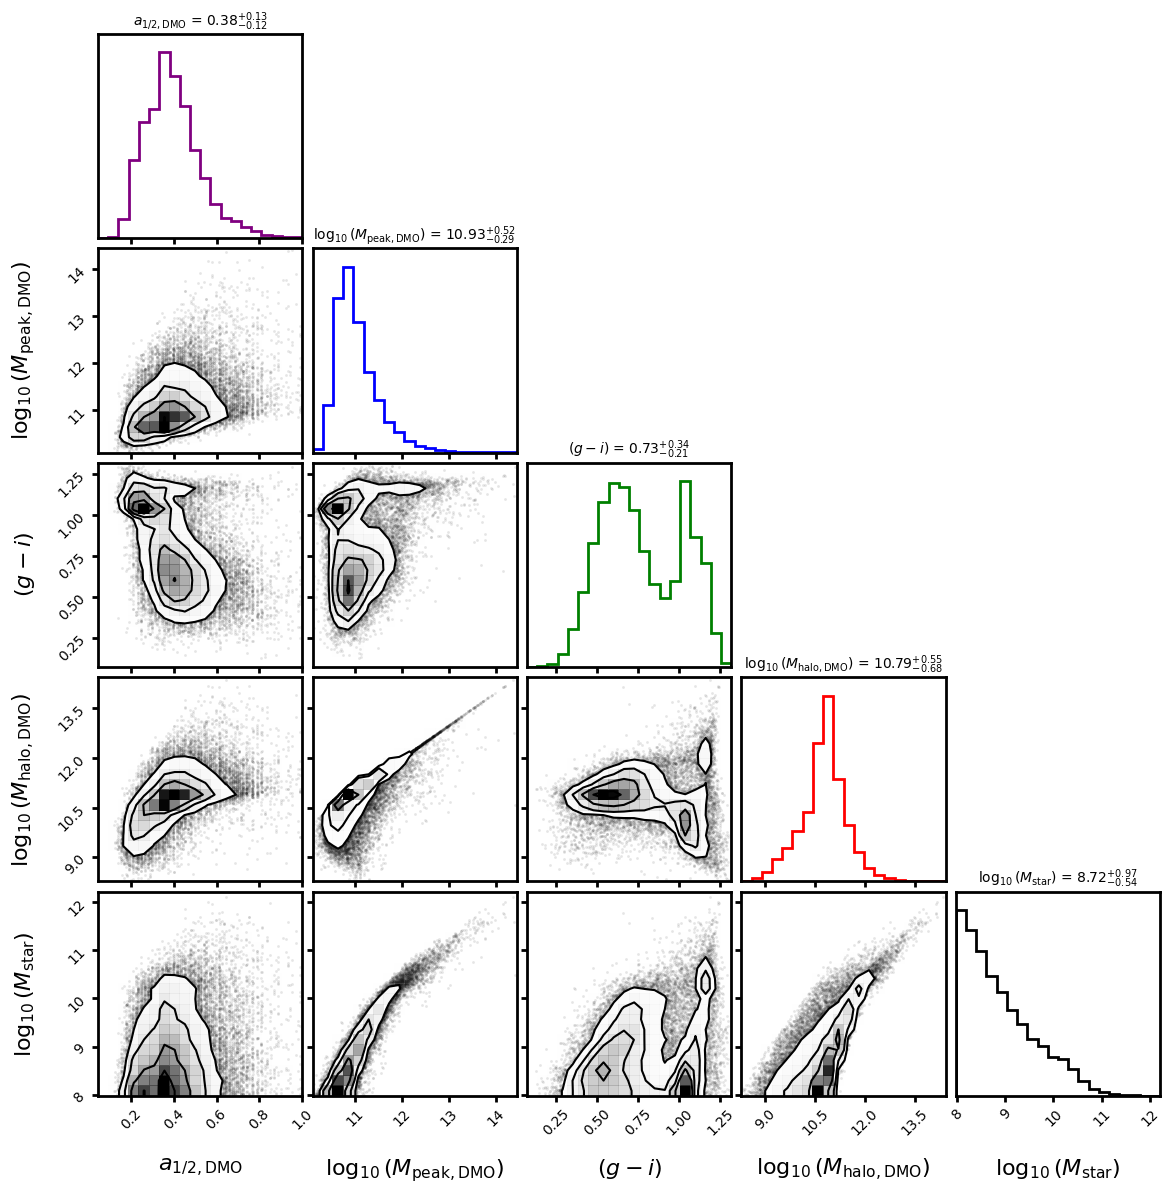

In [13]:
import corner
import matplotlib.pyplot as plt
import numpy as np

print("Unmatched corner plot")

# Stack data
unmatched_data = np.vstack([
    data['a12'],
    np.log10(data['mpeak']),
    data['color'],
    np.log10(data['SubhaloMass']),
    np.log10(data['StellarMass'])
]).T

# Create corner plot
figure = corner.corner(
    unmatched_data,
    labels=[
        r"$a_{1/2, \rm DMO}$",
        r"$\log_{10}(M_{\rm peak, DMO})$",
        r"$(g-i)$",
        r"$\log_{10}(M_{\rm halo, DMO})$",
        r"$\log_{10}(M_{\rm star})$"
    ],
    show_titles=True,
    title_fmt=".2f",
    label_kwargs={"fontsize": 16},
    title_kwargs={"fontsize": 10},
    hist_kwargs={
        "linewidth": 2,
        "histtype": "step"
    },
    smooth=None,
    figsize=(10, 10)
)

# Adjust layout
figure.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.98,
    wspace=0.05,
    hspace=0.05
)

# Thicken axes
for ax in figure.get_axes():
    for spine in ax.spines.values():
        spine.set_linewidth(2)

    ax.tick_params(width=2, length=4)

# Colors in SAME order as data columns
colors = ["purple", "blue", "green", "red", "black"]

# Reshape axes into grid
axes = np.array(figure.axes).reshape((5, 5))

for i in range(5):
    ax = axes[i, i]

    for patch in ax.patches:
        patch.set_edgecolor(colors[i])
        patch.set_facecolor("none")
        patch.set_linewidth(2)

figure.savefig("corner_plot_unmatched.png", dpi=300, bbox_inches="tight")
plt.show()

Matched corner plot


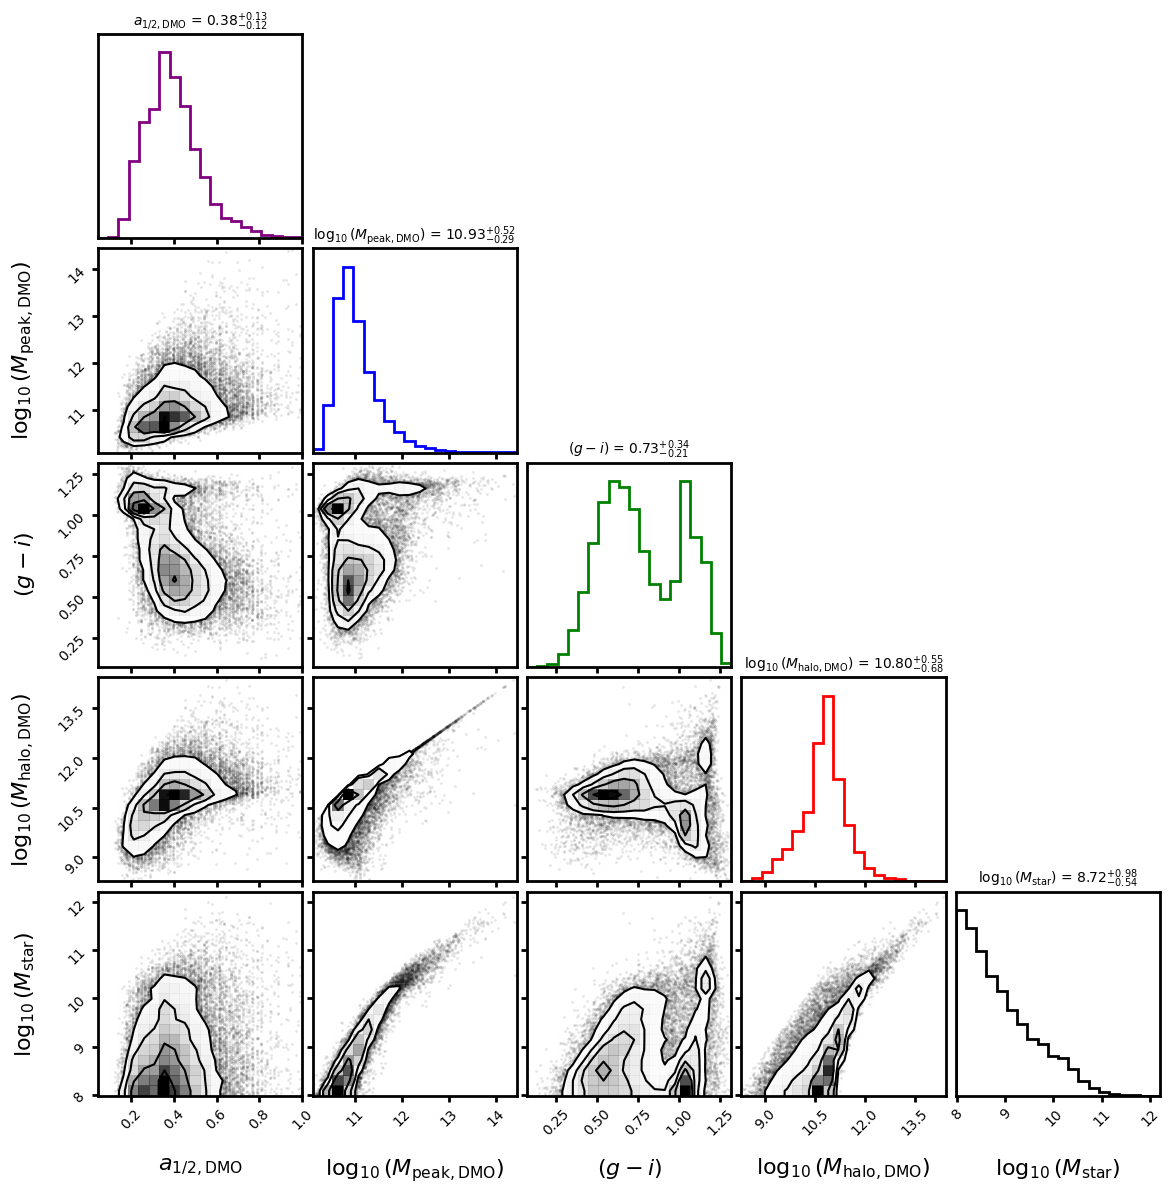

In [14]:
import corner
import matplotlib.pyplot as plt
import numpy as np


data = data[data['subhalomass_matched'] > 0]
data = data[data['stellarmass_matched'] > 0]

print("Matched corner plot")

# Stack for corner plot
matched_data = np.vstack([data['a12_matched'], 
                            np.log10(data['mpeak_matched']),
                            data['color_matched'],
                            np.log10(data['subhalomass_matched']),
                            np.log10(data['stellarmass_matched'])]).T

# Create corner plot
figure = corner.corner(
    matched_data,
    labels=[
        r"$a_{1/2, \rm DMO}$",
        r"$\log_{10}(M_{\rm peak, DMO})$",
        r"$(g-i)$",
        r"$\log_{10}(M_{\rm halo, DMO})$",
        r"$\log_{10}(M_{\rm star})$"
    ],
    show_titles=True,
    title_fmt=".2f",
    label_kwargs={"fontsize": 16},
    title_kwargs={"fontsize": 10},
    hist_kwargs={
        "linewidth": 2,
        "histtype": "step"
    },
    smooth=None,
    figsize=(10, 10)
)

# Adjust layout
figure.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.98,
    wspace=0.05,
    hspace=0.05
)

# Thicken axes
for ax in figure.get_axes():
    for spine in ax.spines.values():
        spine.set_linewidth(2)

    ax.tick_params(width=2, length=4)

# Colors in SAME order as data columns
colors = ["purple", "blue", "green", "red", "black"]

# Reshape axes into grid
axes = np.array(figure.axes).reshape((5, 5))

for i in range(5):
    ax = axes[i, i]

    for patch in ax.patches:
        patch.set_edgecolor(colors[i])
        patch.set_facecolor("none")
        patch.set_linewidth(2)

figure.savefig("corner_plot_matched.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
hydro_data_mpeak_cut = data[(data['mpeak_matched'] >= (10**11))&(data['mpeak_matched'] <= (10**12))]
print(len(hydro_data_mpeak_cut))

10559


In [16]:
hydro_mstar_mpeak_cut = data[(np.log10(data['stellarmass_matched']) > 9.5) & (np.log10(data['stellarmass_matched']) < 10.2)]
print(len(hydro_mstar_mpeak_cut))

3827


In [17]:
from multicam_tng_utils import get_msmhmr

In [18]:
log10_stellar_mass = np.array(np.log10(hydro_data_mpeak_cut['stellarmass_matched']))
log10_mpeak = np.array(np.log10(hydro_data_mpeak_cut['mpeak_matched']))

m_star_dev, (m, b) = get_msmhmr(log10_stellar_mass, 
                                log10_mpeak,
                                mass_bin = (11, 12), n_bins = 11)
print(m_star_dev, (m, b))

[-0.03895806  0.09968563 -0.09038291 ...  0.22567343  0.13283112
 -0.07381422] (np.float64(0.5353597543249119), np.float64(-7.990175626140006))


In [19]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font size for all text elements (optional, can be overridden)
mpl.rcParams['font.size'] = 25

# Set global font size for axis labels
mpl.rcParams['axes.labelsize'] = 30

# Set global font size for tick numbers
mpl.rcParams['xtick.labelsize'] = 20
mpl.rcParams['ytick.labelsize'] = 20

# Set tick widths and sizes globally
mpl.rcParams['xtick.major.width'] = 3
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['ytick.major.size'] = 5

# Set axes line width globally
mpl.rcParams['axes.linewidth'] = 3 # Sets the width of the spines

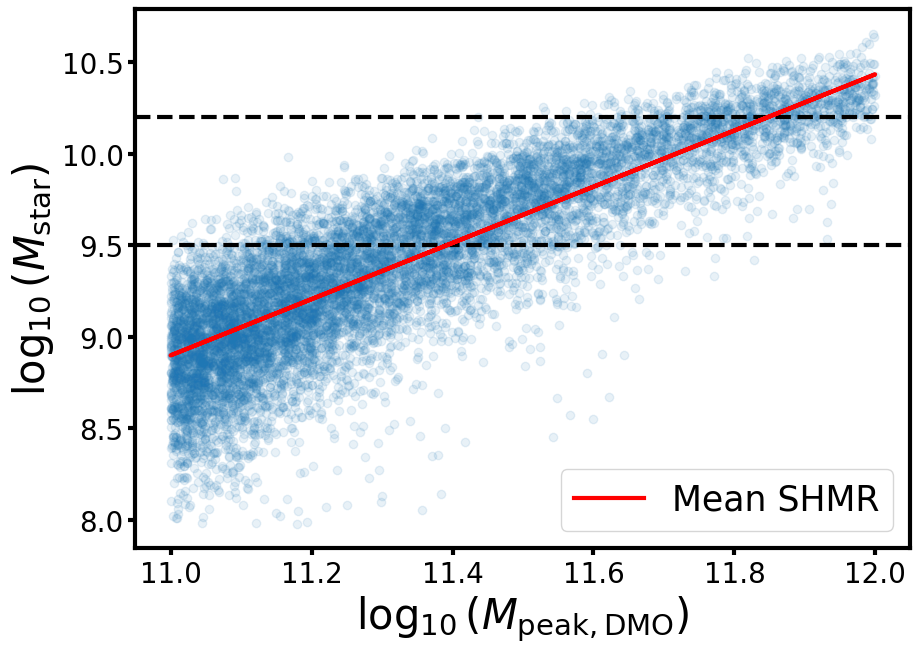

In [20]:
plt.figure(figsize=(10, 7))
plt.scatter(np.log10(np.array(hydro_data_mpeak_cut['mpeak_matched'])), np.log10(np.array(hydro_data_mpeak_cut['stellarmass_matched'])), alpha = .1);
plt.xlabel(r"$\log_{10}(M_{\rm peak, DMO})$");
plt.ylabel(r"$\log_{10}(M_{\rm star})$");
#plt.ylim(9.5, 10.2)
plt.axhline(y=9.5, color='k', linestyle='--', linewidth=3)
plt.axhline(y=10.2, color='k', linestyle='--', linewidth=3)
ypred = np.log10(10 ** (m * log10_mpeak + b) * 10**log10_mpeak)
plt.plot(log10_mpeak, ypred, color = "red", linewidth=3, label = "Mean SHMR");
plt.legend(loc = 'lower right');
plt.savefig('dmo_figure_3.png', bbox_inches='tight', dpi=300)

In [21]:
hydro_data_mpeak_cut['m_star_dev'] = m_star_dev
hydro_mstar_mpeak_cut = hydro_data_mpeak_cut[(np.log10(hydro_data_mpeak_cut['stellarmass_matched']) > 9.5) & (np.log10(hydro_data_mpeak_cut['stellarmass_matched']) < 10.2)]
print(len(hydro_mstar_mpeak_cut))

3777


/tmp/ipykernel_41315/1251908993.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hydro_data_mpeak_cut['m_star_dev'] = m_star_dev


In [22]:
hydro_mstar_mpeak_cut

,a12,mpeak,color,StellarMass,SubhaloMass,SubhaloFlag,a12_matched,mpeak_matched,color_matched,stellarmass_matched,subhalomass_matched,m_star_dev
26,0.290698,3.719824e+11,1.093975,1.426524e+10,3.041727e+11,True,0.290698,3.719824e+11,1.093975,1.426524e+10,3.041727e+11,0.379540
27,0.354610,2.919132e+11,0.535936,8.203994e+09,2.883535e+11,True,0.354610,2.919132e+11,0.535936,8.203994e+09,2.883535e+11,0.300912
28,0.444444,4.735706e+11,1.061354,1.061568e+10,3.212165e+11,True,0.444444,4.735706e+11,1.061354,1.061568e+10,3.212165e+11,0.090208
29,0.322581,4.341942e+11,1.086931,1.394747e+10,3.033128e+11,True,0.322581,4.341942e+11,1.086931,1.394747e+10,3.033128e+11,0.266639
30,0.233645,6.563159e+11,1.197269,1.564545e+10,2.849926e+11,True,0.233645,6.563159e+11,1.197269,1.564545e+10,2.849926e+11,0.041044
...,...,...,...,...,...,...,...,...,...,...,...,...
44595,0.222717,1.287206e+11,1.157442,4.439557e+09,7.665917e+10,True,0.222717,1.287206e+11,1.157442,4.439557e+09,7.665917e+10,0.580209
44884,0.268097,1.488721e+11,0.955601,3.336155e+09,8.242960e+10,True,0.268097,1.488721e+11,0.955601,3.336155e+09,8.242960e+10,0.359134
45387,0.249377,1.493470e+11,1.116285,3.281747e+09,8.009921e+10,True,0.249377,1.493470e+11,1.116285,3.281747e+09,8.009921e+10,0.349869
47111,0.558659,2.114314e+11,1.082733,3.262727e+09,6.160211e+10,True,0.558659,2.114314e+11,1.082733,3.262727e+09,6.160211e+10,0.115547


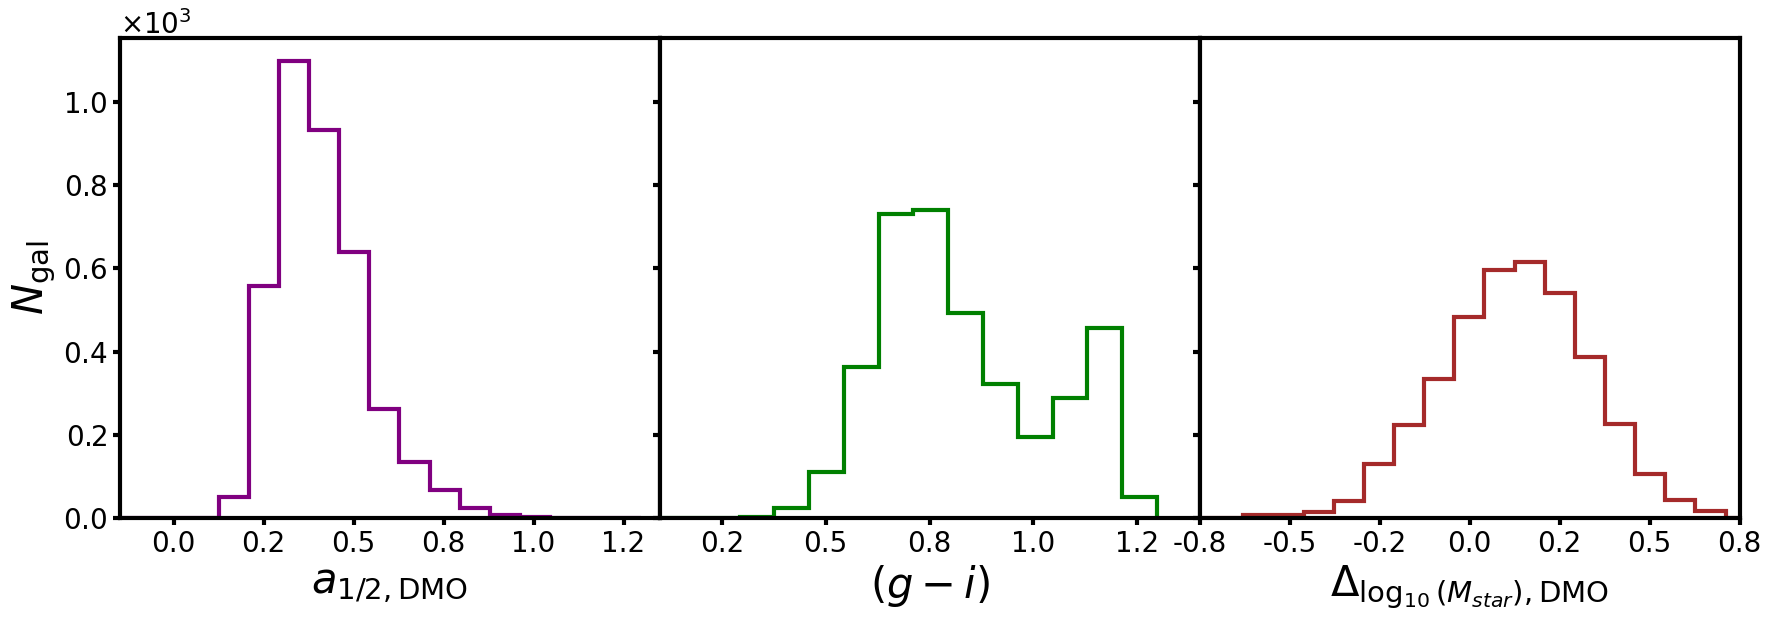

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

masses = [
    np.array(hydro_mstar_mpeak_cut['a12_matched']),
    np.array(hydro_mstar_mpeak_cut['color_matched']),
    np.array(hydro_mstar_mpeak_cut['m_star_dev']),
]

labels = [
    r'$a_{1/2, \rm DMO}$',
    r'$(g - i)$',
    r'$\Delta _{\log_{10} (M_{star}), \rm DMO}$'
]

color_list = ['purple', 'g', 'brown']

# Define common bin edges
bins = np.linspace(
    min(np.min(m) for m in masses),
    max(np.max(m) for m in masses),
    26  # 25 bins
)

# Create a 1x3 grid of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, mass, label, color in zip(axes, masses, labels, color_list):
    ax.hist(
        mass,
        bins=bins,
        histtype='step',
        linewidth=3,
        color=color
    )
    ax.set_xlabel(label)

# Shared y-label
axes[0].set_ylabel(r'$N_{\rm gal}$')

# Scientific notation on y-axis
for ax in axes:
    ax.yaxis.set_major_formatter(
        ticker.ScalarFormatter(useMathText=True)
    )
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

# Adjust layout to remove space between subplots
plt.subplots_adjust(wspace=0, left=0.05, right=0.95, bottom=0.1, top=0.9)

    
axes[0].set_xlim(-0.15, 1.35)
axes[1].set_xlim(0.1, 1.4)
axes[2].set_xlim(-0.75, 0.75)

from matplotlib.ticker import FormatStrFormatter

for ax in axes:
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))

plt.savefig('dmo_figure_4.png', bbox_inches='tight', dpi=300)
#plt.show()
